Import Dataset 

In [3]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Load the JSON and inspect the first sweep

In [4]:
current = Path.cwd().resolve()
project_root = next(
    path for path in (current, *current.parents)
    if (path / "pyproject.toml").is_file()
)

data_path = project_root / "data" / "raw" / "N45B-nmos1.json"

with data_path.open(encoding="utf-8") as file:
    mesd = json.load(file)

sweeps = pd.DataFrame(mesd["Records"])

print({key: value for key, value in mesd.items() if key != "Records"})
print(f"Number of sweeps = {len(sweeps):,}")

columns = ["W", "L", "Temp", "Corner", "Vds", "Vgs", "Ids"]
display(sweeps.loc[[0], columns])

{'PDK': 'N45B', 'Node': 45, 'Model': 'BSIM4.3', 'Device': 'nmos1', 'Type': 'NMOS', 'Simulator': 'spectre'}
Number of sweeps = 9,000


,W,L,Temp,Corner,Vds,Vgs,Ids
0,120,60,-40,tt,0.0,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ...","[0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0..."


Making one row per operating point 

In [5]:
df = (
    sweeps[columns]
    .rename_axis("sweep_id")
    .explode(["Vgs", "Ids"])
    .reset_index()
    .astype({"Vgs": float, "Ids": float})
)

print(f"Number of operating points = {len(df):,}")
display(df.head())

summary = df[columns].describe(include="all").T
summary["missing"] = df[columns].isna().sum()
summary["unique_values"] = df[columns].nunique()
display(summary[["unique_values", "missing", "min", "max"]])

Number of operating points = 99,000


,sweep_id,W,L,Temp,Corner,Vds,Vgs,Ids
0,0,120,60,-40,tt,0.0,0.0,1.059800e-48
1,0,120,60,-40,tt,0.0,0.1,-1.635900e-15
2,0,120,60,-40,tt,0.0,0.2,-8.017000e-15
3,0,120,60,-40,tt,0.0,0.3,-2.346700e-14
4,0,120,60,-40,tt,0.0,0.4,-6.148500e-14


,unique_values,missing,min,max
W,10,0,120.0,1000.0
L,10,0,60.0,1000.0
Temp,5,0,-40.0,125.0
Corner,3,0,NaN,NaN
Vds,6,0,0.0,1.0
Vgs,11,0,0.0,1.0
Ids,87960,0,-0.0,0.000565


Audit the voltage sweeps

In [6]:
positive_bias_sweeps = sweeps.loc[sweeps["Vds"] > 0].copy()
curve_signatures = [
    (tuple(vgs), tuple(ids))
    for vgs, ids in zip(positive_bias_sweeps["Vgs"], positive_bias_sweeps["Ids"], strict=True)
]
duplicate_sweeps = len(curve_signatures) - len(set(curve_signatures))

corner_currents = (
    positive_bias_sweeps.assign(
        on_current=positive_bias_sweeps["Ids"].map(lambda values: values[-1])
    )
    .pivot(index=["W", "L", "Temp", "Vds"], columns="Corner", values="on_current")
)
ordered = (corner_currents["ff"] > corner_currents["tt"]) & (
    corner_currents["tt"] > corner_currents["ss"]
)

print(f"Positive-bias sweeps = {len(positive_bias_sweeps):,}")
print(f"Exact repeats beyond the first occurrence = {duplicate_sweeps:,}")
print(f"Matched conditions with ff > tt > ss = {ordered.sum():,} / {len(ordered):,}")

nonpositive = df.loc[df["Ids"] <= 0]
print(f"Nonpositive currents at zero drain bias = {nonpositive['Vds'].eq(0).sum():,}")
print(f"Nonpositive currents at positive drain bias = {nonpositive['Vds'].gt(0).sum():,}")

Positive-bias sweeps = 7,500
Exact repeats beyond the first occurrence = 0
Matched conditions with ff > tt > ss = 2,500 / 2,500
Nonpositive currents at zero drain bias = 16,490
Nonpositive currents at positive drain bias = 0


Plot drain current on a linear scale

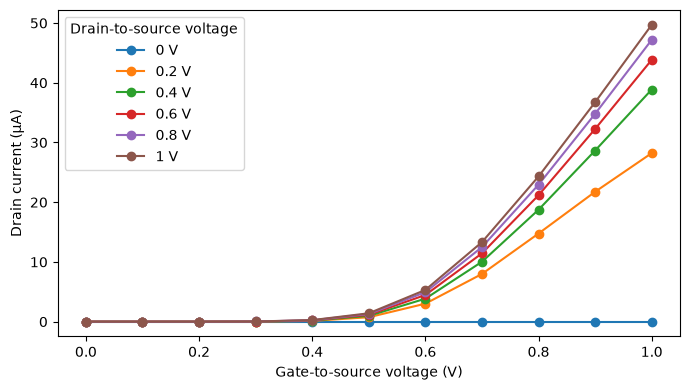

In [7]:
curves = df.query("W == 120 and L == 60 and Temp == 25 and Corner == 'tt'")

fig, ax = plt.subplots(figsize=(7, 4))

for vds, curve in curves.sort_values("Vgs").groupby("Vds"):
    ax.plot(curve["Vgs"], curve["Ids"] * 1e6, marker="o", label=f"{vds:g} V")

ax.set(
    xlabel="Gate-to-source voltage (V)",
    ylabel="Drain current (µA)",
)
ax.legend(title="Drain-to-source voltage")
fig.tight_layout()
plt.show()

Plot drain current on a logarithmic scale

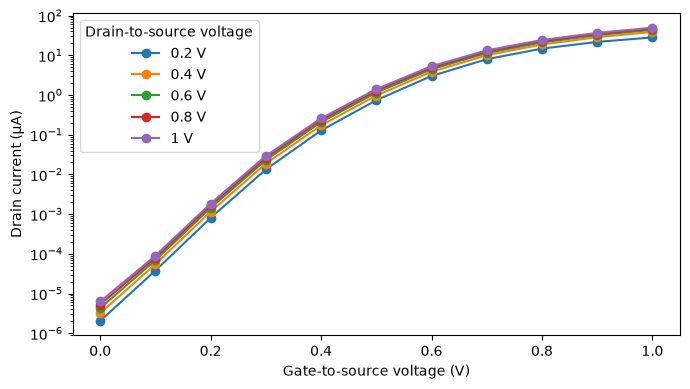

In [8]:
log_curves = curves.loc[(curves["Vds"] > 0) & (curves["Ids"] > 0)]

fig, ax = plt.subplots(figsize=(7, 4))
for vds, curve in log_curves.sort_values("Vgs").groupby("Vds"):
    ax.plot(curve["Vgs"], curve["Ids"] * 1e6, marker="o", label=f"{vds:g} V")

ax.set(
    yscale="log",
    xlabel="Gate-to-source voltage (V)",
    ylabel="Drain current (µA)",
)
ax.legend(title="Drain-to-source voltage")
fig.tight_layout()
plt.show()